# Spaceship Titanic — VS Code (Local)

Notebook ini dijalankan secara lokal melalui VS Code/Jupyter Notebook. Dataset dibaca dari folder `data/` di dalam project, dan seluruh hasil eksperimen disimpan ke folder `outputs/`.

In [1]:
# 1. Persiapan environment dan direktori project
from pathlib import Path
import os
import warnings
import json
import joblib
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

# Deteksi folder dataset secara fleksibel.
REQUIRED_FILES = {"train.csv", "test.csv", "sample_submission.csv"}
START_DIR = Path.cwd()

def contains_competition_files(folder: Path) -> bool:
    return folder.is_dir() and all((folder / filename).is_file() for filename in REQUIRED_FILES)

candidate_dirs = [
    START_DIR / "data",
    START_DIR / "dataset",
    START_DIR / "Datasets",
    START_DIR,
    START_DIR.parent / "data",
    START_DIR.parent / "Spaceship_Titanic_VSCode" / "data",
    Path(r"D:\MKA\PMA\Spaceship_Titanic_VSCode\data"),
]

DATA_DIR = next((folder for folder in candidate_dirs if contains_competition_files(folder)), None)

# Jika folder tidak ditemukan pada lokasi umum, cari terbatas di dalam workspace dan parent-nya.
if DATA_DIR is None:
    search_roots = [START_DIR, START_DIR.parent]
    for root in search_roots:
        if root.exists():
            for candidate in root.glob("**/train.csv"):
                if contains_competition_files(candidate.parent):
                    DATA_DIR = candidate.parent
                    break
        if DATA_DIR is not None:
            break

if DATA_DIR is None:
    raise FileNotFoundError(
        "Dataset tidak ditemukan. Pastikan train.csv, test.csv, dan "
        "sample_submission.csv berada di folder 'data' pada project.\n"
        f"Folder kerja saat ini: {START_DIR}"
    )

# Project root adalah folder induk data/ (atau folder yang berisi file CSV).
PROJECT_DIR = DATA_DIR.parent if DATA_DIR.name.lower() in {"data", "dataset", "datasets"} else DATA_DIR
OUTPUT_DIR = PROJECT_DIR / "outputs"
MODEL_DIR = OUTPUT_DIR / "models"
PLOT_DIR = OUTPUT_DIR / "plots"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

print("Python project siap.")
print("Working directory :", START_DIR)
print("Project directory :", PROJECT_DIR)
print("Dataset directory :", DATA_DIR)
print("Output directory  :", OUTPUT_DIR)

Python project siap.
Working directory : d:\MKA\PMA\Spaceship_Titanic_VSCode
Project directory : d:\MKA\PMA\Spaceship_Titanic_VSCode
Dataset directory : d:\MKA\PMA\Spaceship_Titanic_VSCode\data
Output directory  : d:\MKA\PMA\Spaceship_Titanic_VSCode\outputs


## 2. Membaca dataset lokal

Pastikan folder project memiliki struktur `data/train.csv`, `data/test.csv`, dan `data/sample_submission.csv`. Tidak perlu upload ZIP melalui notebook.

## 3. Membaca file kompetisi

In [2]:
# Baca dataset lokal dari folder data/
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
sample_submission = pd.read_csv(DATA_DIR / "sample_submission.csv")

print("Dataset directory:", DATA_DIR)
print("Train shape:", train.shape)
print("Test shape :", test.shape)
print("Sample submission shape:", sample_submission.shape)

display(train.head())
display(test.head())
display(sample_submission.head())

Dataset directory: d:\MKA\PMA\Spaceship_Titanic_VSCode\data
Train shape: (8693, 14)
Test shape : (4277, 13)
Sample submission shape: (4277, 2)


,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name
0,0013_01,Earth,True,G/3/S,TRAPPIST-1e,27.0,False,0.0,0.0,0.0,0.0,0.0,Nelly Carsoning
1,0018_01,Earth,False,F/4/S,TRAPPIST-1e,19.0,False,0.0,9.0,0.0,2823.0,0.0,Lerome Peckers
2,0019_01,Europa,True,C/0/S,55 Cancri e,31.0,False,0.0,0.0,0.0,0.0,0.0,Sabih Unhearfus
3,0021_01,Europa,False,C/1/S,TRAPPIST-1e,38.0,False,0.0,6652.0,0.0,181.0,585.0,Meratz Caltilter
4,0023_01,Earth,False,F/5/S,TRAPPIST-1e,20.0,False,10.0,0.0,635.0,0.0,0.0,Brence Harperez


,PassengerId,Transported
0,0013_01,False
1,0018_01,False
2,0019_01,False
3,0021_01,False
4,0023_01,False


## 4. Pemeriksaan awal dan target

Train info:
<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   str    
 1   HomePlanet    8492 non-null   str    
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   str    
 4   Destination   8511 non-null   str    
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   str    
 13  Transported   8693 non-null   bool   
dtypes: bool(1), float64(6), object(2), str(5)
memory usage: 1.2+ MB
\nDistribusi target:


,count
Transported,
True,4378
False,4315


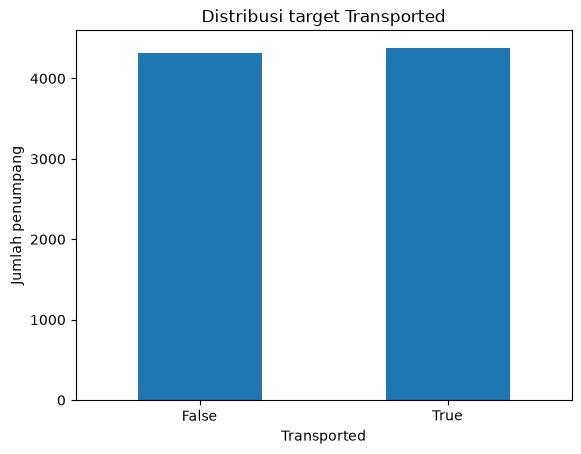

,missing_count,missing_percent
CryoSleep,217,2.50
ShoppingMall,208,2.39
VIP,203,2.34
HomePlanet,201,2.31
Name,200,2.30
Cabin,199,2.29
VRDeck,188,2.16
Spa,183,2.11
FoodCourt,183,2.11
Destination,182,2.09


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,8693,8693,0001_01,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
HomePlanet,8492,3,Earth,4602,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CryoSleep,8476,2,False,5439,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Cabin,8494,6560,G/734/S,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Destination,8511,3,TRAPPIST-1e,5915,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,8514.0,NaN,NaN,NaN,28.82793,14.489021,0.0,19.0,27.0,38.0,79.0
VIP,8490,2,False,8291,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RoomService,8512.0,NaN,NaN,NaN,224.687617,666.717663,0.0,0.0,0.0,47.0,14327.0
FoodCourt,8510.0,NaN,NaN,NaN,458.077203,1611.48924,0.0,0.0,0.0,76.0,29813.0
ShoppingMall,8485.0,NaN,NaN,NaN,173.729169,604.696458,0.0,0.0,0.0,27.0,23492.0


In [3]:
assert 'Transported' in train.columns, 'Kolom target Transported tidak ditemukan.'
assert 'PassengerId' in test.columns, 'Kolom PassengerId tidak ditemukan di test.'

print('Train info:')
train.info()
print('\\nDistribusi target:')
display(train['Transported'].value_counts(dropna=False).rename_axis('Transported').to_frame('count'))

ax = train['Transported'].value_counts().reindex([False, True]).plot(kind='bar', rot=0)
ax.set_title('Distribusi target Transported')
ax.set_xlabel('Transported')
ax.set_ylabel('Jumlah penumpang')
plt.show()

missing = pd.DataFrame({
    'missing_count': train.isna().sum(),
    'missing_percent': (train.isna().mean() * 100).round(2)
}).sort_values('missing_count', ascending=False)
display(missing)
display(train.describe(include='all').T)


## 5. Visualisasi EDA

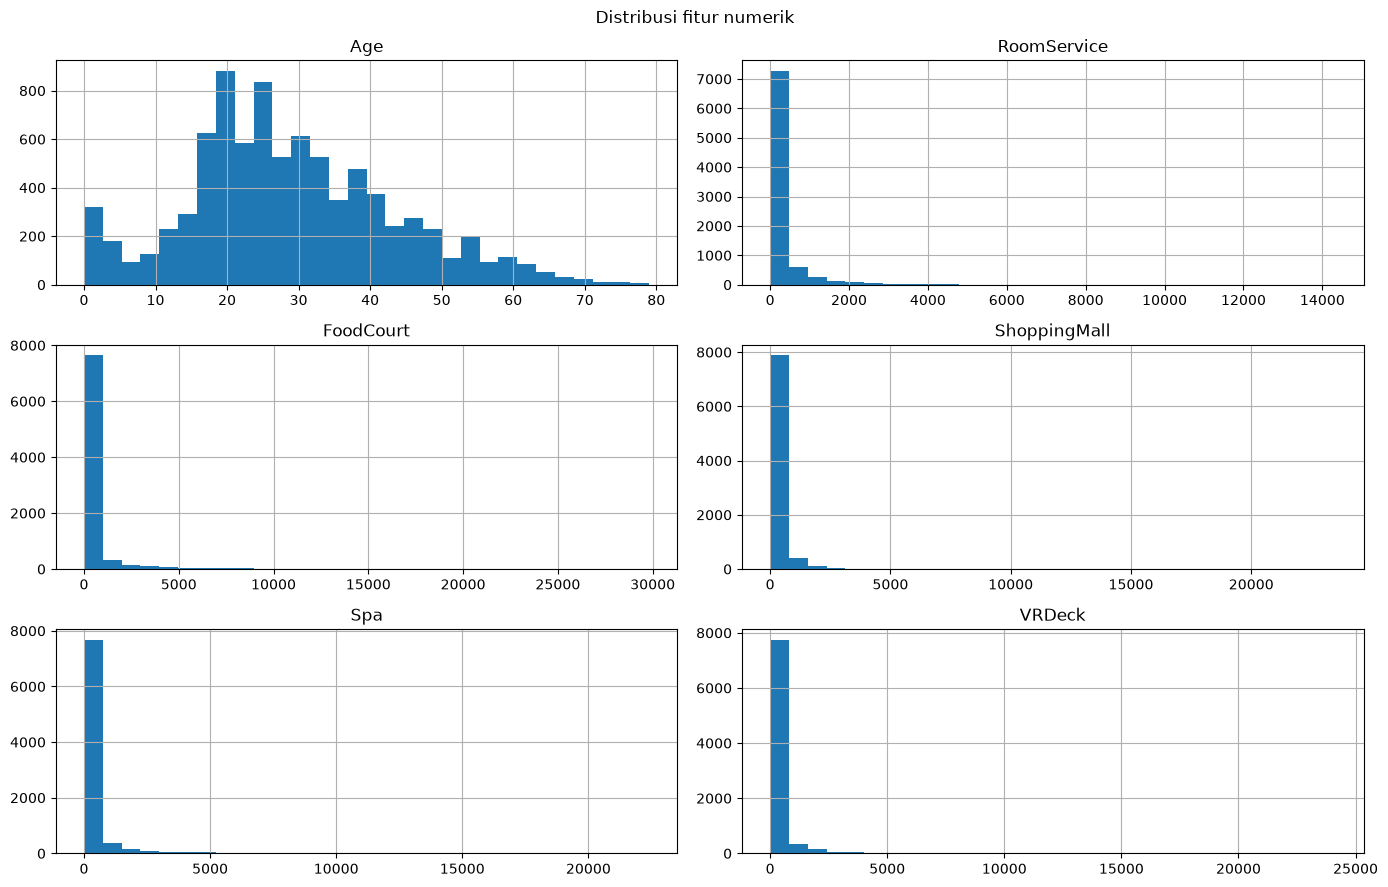

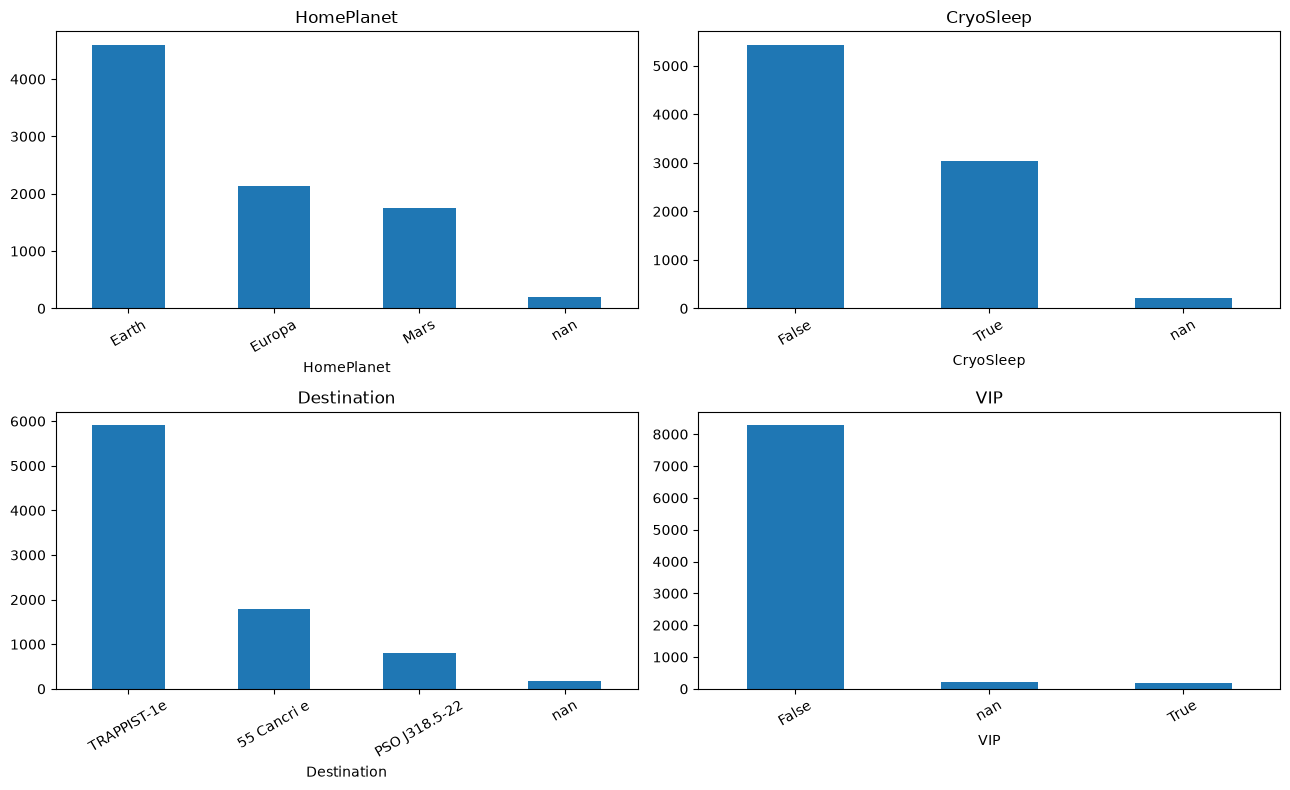

In [4]:
numeric_original = ['Age', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']
train[numeric_original].hist(figsize=(14, 9), bins=30)
plt.suptitle('Distribusi fitur numerik')
plt.tight_layout()
plt.show()

categorical_original = ['HomePlanet', 'CryoSleep', 'Destination', 'VIP']
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for col, ax in zip(categorical_original, axes.ravel()):
    train[col].value_counts(dropna=False).plot(kind='bar', ax=ax)
    ax.set_title(col)
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()


## 6. Feature engineering

Fitur turunan yang digunakan:
- `GroupSize`: jumlah penumpang dengan awalan `PassengerId` yang sama. Dihitung dari gabungan train dan test karena informasi keanggotaan grup tersedia pada kedua file.
- `Deck`, `CabinNum`, `Side`: hasil parsing `Cabin` dengan format `deck/number/side`.
- `TotalSpend`, `SpendCount`, `SpendingMissingCount`, `NoSpending`: pola pengeluaran fasilitas kapal.
- `AgeGroup`: kelompok usia.

Kolom identifier mentah dan `Name` tidak langsung dimasukkan ke model. Transformasi fitur tidak menggunakan nilai target test.

In [5]:
SPEND_COLS = ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']

# Hitung ukuran grup dari train + test supaya tidak mengabaikan anggota grup
# yang kebetulan berada di file test.
all_passengers = pd.concat([
    train.drop(columns=['Transported']).assign(_source='train'),
    test.assign(_source='test')
], ignore_index=True)
all_passengers['_GroupId'] = all_passengers['PassengerId'].astype('string').str.split('_').str[0]
group_size_map = all_passengers['_GroupId'].value_counts().to_dict()

def make_features(df):
    df = df.copy()

    group_id = df['PassengerId'].astype('string').str.split('_').str[0]
    df['GroupSize'] = group_id.map(group_size_map).astype(float)

    cabin = df['Cabin'].astype('string').str.split('/', expand=True)
    df['Deck'] = cabin[0]
    df['CabinNum'] = pd.to_numeric(cabin[1], errors='coerce')
    df['Side'] = cabin[2]

    spend = df[SPEND_COLS].apply(pd.to_numeric, errors='coerce')
    df['TotalSpend'] = spend.sum(axis=1, min_count=1)
    df['SpendCount'] = spend.gt(0).sum(axis=1).astype(float)
    df['SpendingMissingCount'] = spend.isna().sum(axis=1).astype(float)

    # NoSpending hanya ditentukan jika lima nilai pengeluaran diketahui semua.
    fully_observed = spend.notna().all(axis=1)
    no_spend = pd.Series(np.nan, index=df.index, dtype='float64')
    no_spend.loc[fully_observed] = (spend.loc[fully_observed].sum(axis=1) == 0).astype(int)
    no_spend.loc[spend.fillna(0).sum(axis=1) > 0] = 0
    df['NoSpending'] = no_spend

    age = pd.to_numeric(df['Age'], errors='coerce')
    df['AgeGroup'] = pd.cut(
        age, bins=[0, 12, 18, 30, 50, 100],
        labels=['Child', 'Teen', 'YoungAdult', 'Adult', 'Senior'],
        include_lowest=True
    ).astype('object')

    for col in ['CryoSleep', 'VIP']:
        df[col] = df[col].astype('object')

    # Hapus identifier mentah, nama, dan cabin mentah setelah parsing.
    df = df.drop(columns=['PassengerId', 'Cabin', 'Name'], errors='ignore')
    return df

X = make_features(train.drop(columns=['Transported']))
X_test = make_features(test)
y = train['Transported'].astype(int)

print('Feature matrix:', X.shape)
print('Test feature matrix:', X_test.shape)
display(X.head())


Feature matrix: (8693, 19)
Test feature matrix: (4277, 19)


,HomePlanet,CryoSleep,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,GroupSize,Deck,CabinNum,Side,TotalSpend,SpendCount,SpendingMissingCount,NoSpending,AgeGroup
0,Europa,False,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,1.0,B,0,P,0.0,0.0,0.0,1.0,Adult
1,Earth,False,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,1.0,F,0,S,736.0,5.0,0.0,0.0,YoungAdult
2,Europa,False,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,2.0,A,0,S,10383.0,4.0,0.0,0.0,Senior
3,Europa,False,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,2.0,A,0,S,5176.0,4.0,0.0,0.0,Adult
4,Earth,False,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,1.0,F,1,S,1091.0,5.0,0.0,0.0,Teen


## 7. Split train-validation

Gunakan stratified split 80:20. Validation set digunakan untuk membandingkan model, test set Kaggle tidak digunakan untuk memilih model.

In [6]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, log_loss,
    matthews_corrcoef, confusion_matrix, classification_report,
    roc_curve, precision_recall_curve
)

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print('Training subset:', X_train.shape)
print('Validation subset:', X_valid.shape)
print('Target rate train:', round(y_train.mean(), 4))
print('Target rate valid:', round(y_valid.mean(), 4))
print('Validation set dipakai untuk membandingkan kandidat model; test Kaggle tidak digunakan untuk pemilihan model.')

Training subset: (6954, 19)
Validation subset: (1739, 19)
Target rate train: 0.5036
Target rate valid: 0.5037
Validation set dipakai untuk membandingkan kandidat model; test Kaggle tidak digunakan untuk pemilihan model.


## 8. Preprocessing pipeline dan model baseline

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier,
    GradientBoostingClassifier, HistGradientBoostingClassifier
)
from sklearn.base import clone

# XGBoost digunakan sebagai kandidat model utama. Instal otomatis bila belum tersedia.
try:
    from xgboost import XGBClassifier
except ImportError:
    import sys, subprocess
    print("XGBoost belum terpasang. Menginstal xgboost...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "xgboost"])
    from xgboost import XGBClassifier

numeric_features = X.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = X.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

# Mendukung versi scikit-learn baru (sparse_output) maupun versi lama (sparse).
def make_onehot_encoder():
    try:
        return OneHotEncoder(handle_unknown='ignore', sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown='ignore', sparse=False)

def make_preprocessor(scale_numeric=False):
    numeric_steps = [('imputer', SimpleImputer(strategy='median'))]
    if scale_numeric:
        numeric_steps.append(('scaler', StandardScaler()))
    numeric_pipeline = Pipeline(steps=numeric_steps)
    categorical_pipeline = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', make_onehot_encoder())
    ])
    return ColumnTransformer(transformers=[
        ('num', numeric_pipeline, numeric_features),
        ('cat', categorical_pipeline, categorical_features)
    ])

# Enam model dilatih dan dievaluasi dengan split serta metrik yang sama.
models = {
    'Logistic Regression': Pipeline([
        ('preprocess', make_preprocessor(scale_numeric=True)),
        ('model', LogisticRegression(max_iter=2000, C=1.0, random_state=RANDOM_STATE))
    ]),
    'Random Forest': Pipeline([
        ('preprocess', make_preprocessor()),
        ('model', RandomForestClassifier(
            n_estimators=400, min_samples_leaf=2, max_features='sqrt',
            random_state=RANDOM_STATE, n_jobs=-1
        ))
    ]),
    'Extra Trees': Pipeline([
        ('preprocess', make_preprocessor()),
        ('model', ExtraTreesClassifier(
            n_estimators=400, min_samples_leaf=2, max_features='sqrt',
            random_state=RANDOM_STATE, n_jobs=-1
        ))
    ]),
    'Gradient Boosting': Pipeline([
        ('preprocess', make_preprocessor()),
        ('model', GradientBoostingClassifier(
            n_estimators=250, learning_rate=0.05, max_depth=3,
            subsample=0.85, random_state=RANDOM_STATE
        ))
    ]),
    'Hist Gradient Boosting': Pipeline([
        ('preprocess', make_preprocessor()),
        ('model', HistGradientBoostingClassifier(
            max_iter=250, learning_rate=0.06, max_leaf_nodes=15,
            l2_regularization=1.0, random_state=RANDOM_STATE
        ))
    ]),
    'XGBoost': Pipeline([
        ('preprocess', make_preprocessor()),
        ('model', XGBClassifier(
            n_estimators=650, max_depth=4, learning_rate=0.03,
            subsample=0.85, colsample_bytree=0.85, min_child_weight=2,
            reg_lambda=2.0, objective='binary:logistic', eval_metric='logloss',
            tree_method='hist', random_state=RANDOM_STATE, n_jobs=-1
        ))
    ])
}

print('Model yang akan dilatih dan dibandingkan:')
for model_name in models:
    print('-', model_name)

Model yang akan dilatih dan dibandingkan:
- Logistic Regression
- Random Forest
- Extra Trees
- Gradient Boosting
- Hist Gradient Boosting
- XGBoost


## 9. Training dan evaluasi validation

In [8]:
results = []
fitted_models = {}
valid_predictions = {}
valid_probabilities = {}

for name, pipeline in models.items():
    print(f'\\nTraining {name} ...')
    pipeline.fit(X_train, y_train)

    # Prediksi kelas dan probabilitas kelas positif (Transported=True).
    valid_pred = pipeline.predict(X_valid).astype(int)
    valid_proba = pipeline.predict_proba(X_valid)[:, 1]

    valid_predictions[name] = valid_pred
    valid_probabilities[name] = valid_proba
    fitted_models[name] = pipeline

    tn, fp, fn, tp = confusion_matrix(y_valid, valid_pred, labels=[0, 1]).ravel()
    specificity = tn / (tn + fp) if (tn + fp) else np.nan

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_valid, valid_pred),
        'Balanced Accuracy': balanced_accuracy_score(y_valid, valid_pred),
        'Precision': precision_score(y_valid, valid_pred, zero_division=0),
        'Recall / Sensitivity': recall_score(y_valid, valid_pred, zero_division=0),
        'Specificity': specificity,
        'F1-Score': f1_score(y_valid, valid_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_valid, valid_proba),
        'PR-AUC (Average Precision)': average_precision_score(y_valid, valid_proba),
        'Log Loss': log_loss(y_valid, valid_proba, labels=[0, 1]),
        'MCC': matthews_corrcoef(y_valid, valid_pred),
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp
    })

    print(
        f"{name}: accuracy={results[-1]['Accuracy']:.5f} | "
        f"F1={results[-1]['F1-Score']:.5f} | "
        f"ROC-AUC={results[-1]['ROC-AUC']:.5f}"
    )

# Peringkat utama mengikuti metrik kompetisi Spaceship Titanic: Accuracy.
results_df = (
    pd.DataFrame(results)
    .sort_values('Accuracy', ascending=False)
    .reset_index(drop=True)
)
display(results_df.style.format({
    col: '{:.4f}' for col in results_df.select_dtypes(include='number').columns
}))

best_model_name = results_df.loc[0, 'Model']
best_model = fitted_models[best_model_name]
best_valid_pred = valid_predictions[best_model_name]
best_valid_proba = valid_probabilities[best_model_name]

print(f'\\nModel terbaik berdasarkan validation accuracy: {best_model_name}')
print(f"Validation accuracy: {results_df.loc[0, 'Accuracy']:.5f}")

\nTraining Logistic Regression ...
Logistic Regression: accuracy=0.78781 | F1=0.79070 | ROC-AUC=0.87305
\nTraining Random Forest ...
Random Forest: accuracy=0.79528 | F1=0.79446 | ROC-AUC=0.87990
\nTraining Extra Trees ...
Extra Trees: accuracy=0.78378 | F1=0.77725 | ROC-AUC=0.87262
\nTraining Gradient Boosting ...
Gradient Boosting: accuracy=0.80391 | F1=0.80896 | ROC-AUC=0.89247
\nTraining Hist Gradient Boosting ...
Hist Gradient Boosting: accuracy=0.79126 | F1=0.79549 | ROC-AUC=0.88744
\nTraining XGBoost ...
XGBoost: accuracy=0.79931 | F1=0.80360 | ROC-AUC=0.89304


,Model,Accuracy,Balanced Accuracy,Precision,Recall / Sensitivity,Specificity,F1-Score,ROC-AUC,PR-AUC (Average Precision),Log Loss,MCC,TN,FP,FN,TP
0,Gradient Boosting,0.8039,0.8038,0.7943,0.8242,0.7833,0.8090,0.8925,0.9023,0.4127,0.6081,676.0000,187.0000,154.0000,722.0000
1,XGBoost,0.7993,0.7992,0.7925,0.8151,0.7833,0.8036,0.8930,0.9042,0.4069,0.5988,676.0000,187.0000,162.0000,714.0000
2,Random Forest,0.7953,0.7954,0.8037,0.7854,0.8053,0.7945,0.8799,0.8907,0.4266,0.5908,695.0000,168.0000,188.0000,688.0000
3,Hist Gradient Boosting,0.7913,0.7911,0.7853,0.8059,0.7764,0.7955,0.8874,0.8992,0.4166,0.5826,670.0000,193.0000,170.0000,706.0000
4,Logistic Regression,0.7878,0.7877,0.7858,0.7957,0.7798,0.7907,0.8730,0.8819,0.4430,0.5756,673.0000,190.0000,179.0000,697.0000
5,Extra Trees,0.7838,0.7840,0.8079,0.7489,0.8192,0.7773,0.8726,0.8825,0.4426,0.5693,707.0000,156.0000,220.0000,656.0000


\nModel terbaik berdasarkan validation accuracy: Gradient Boosting
Validation accuracy: 0.80391


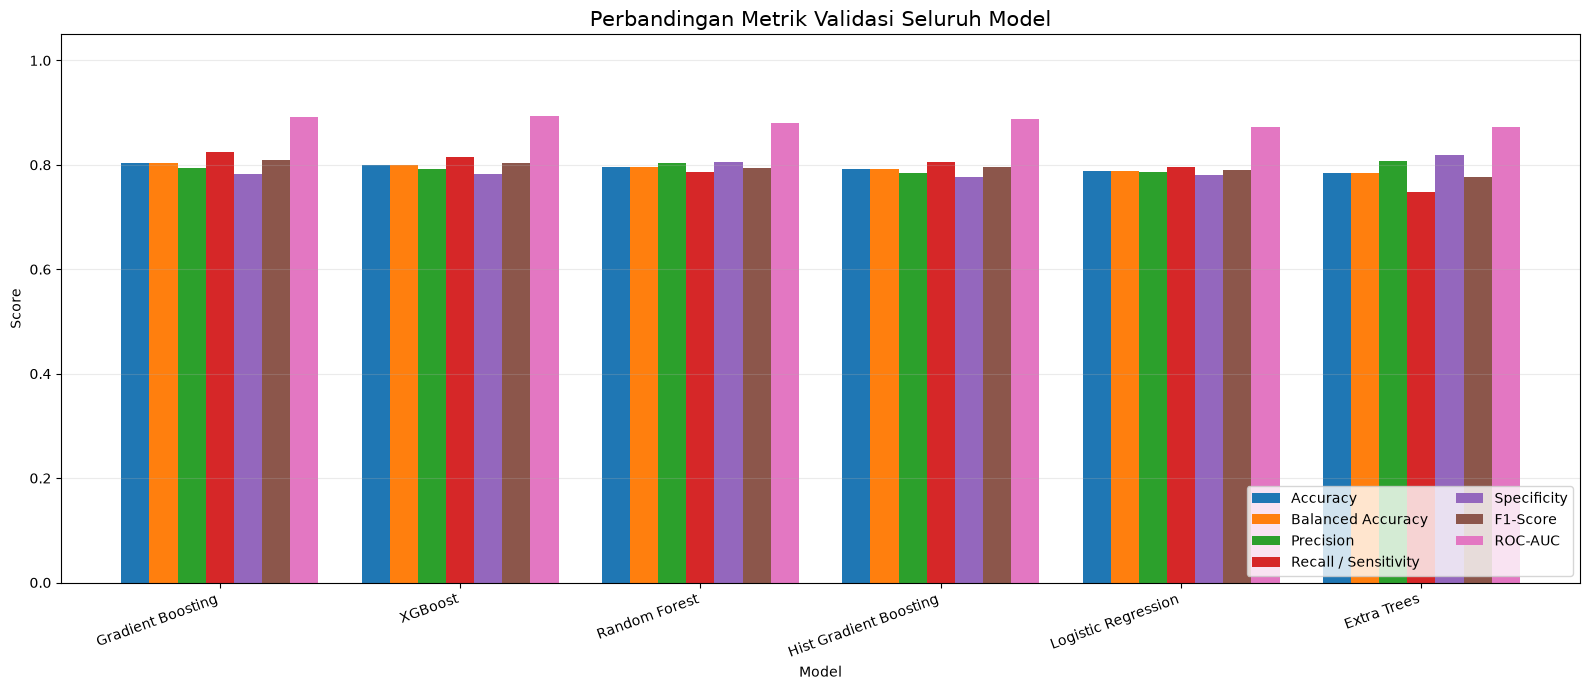

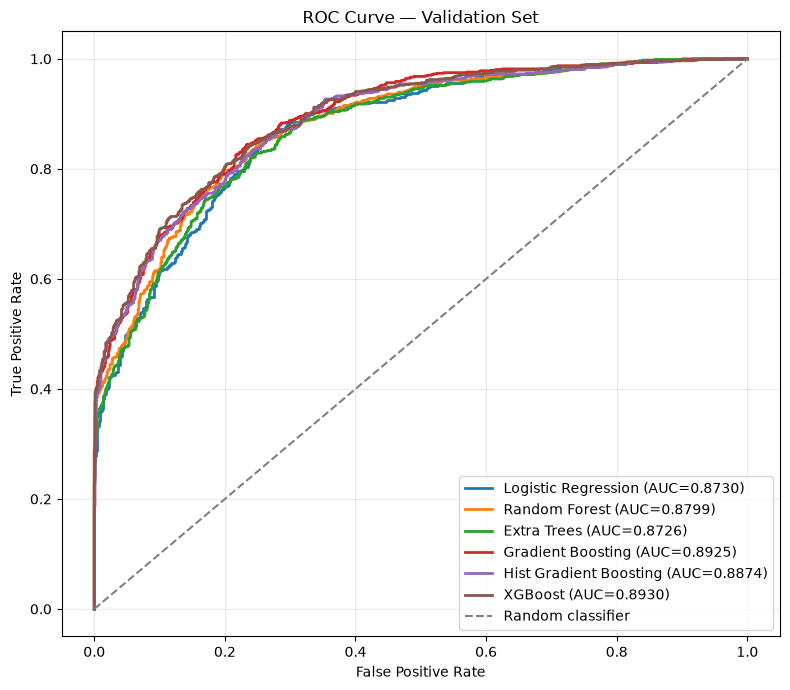

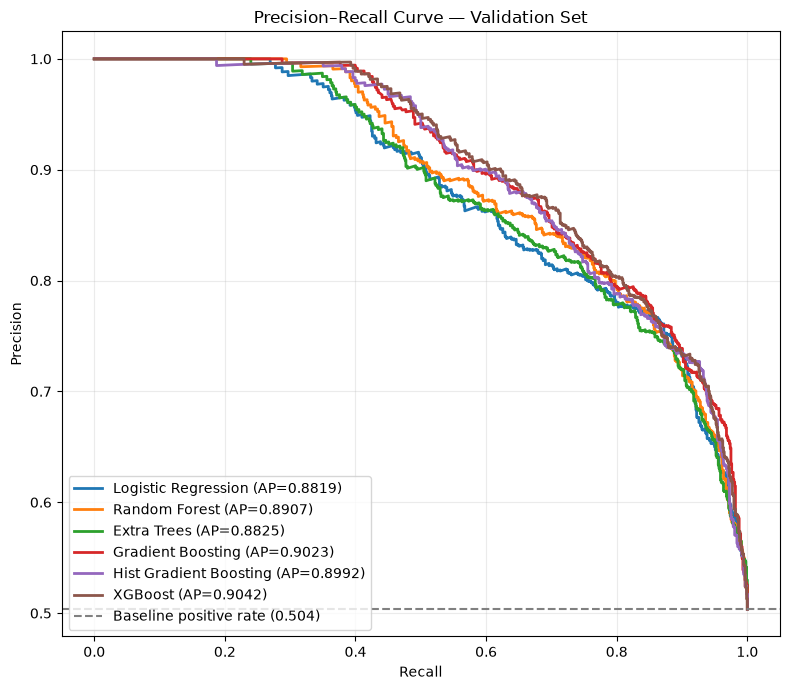

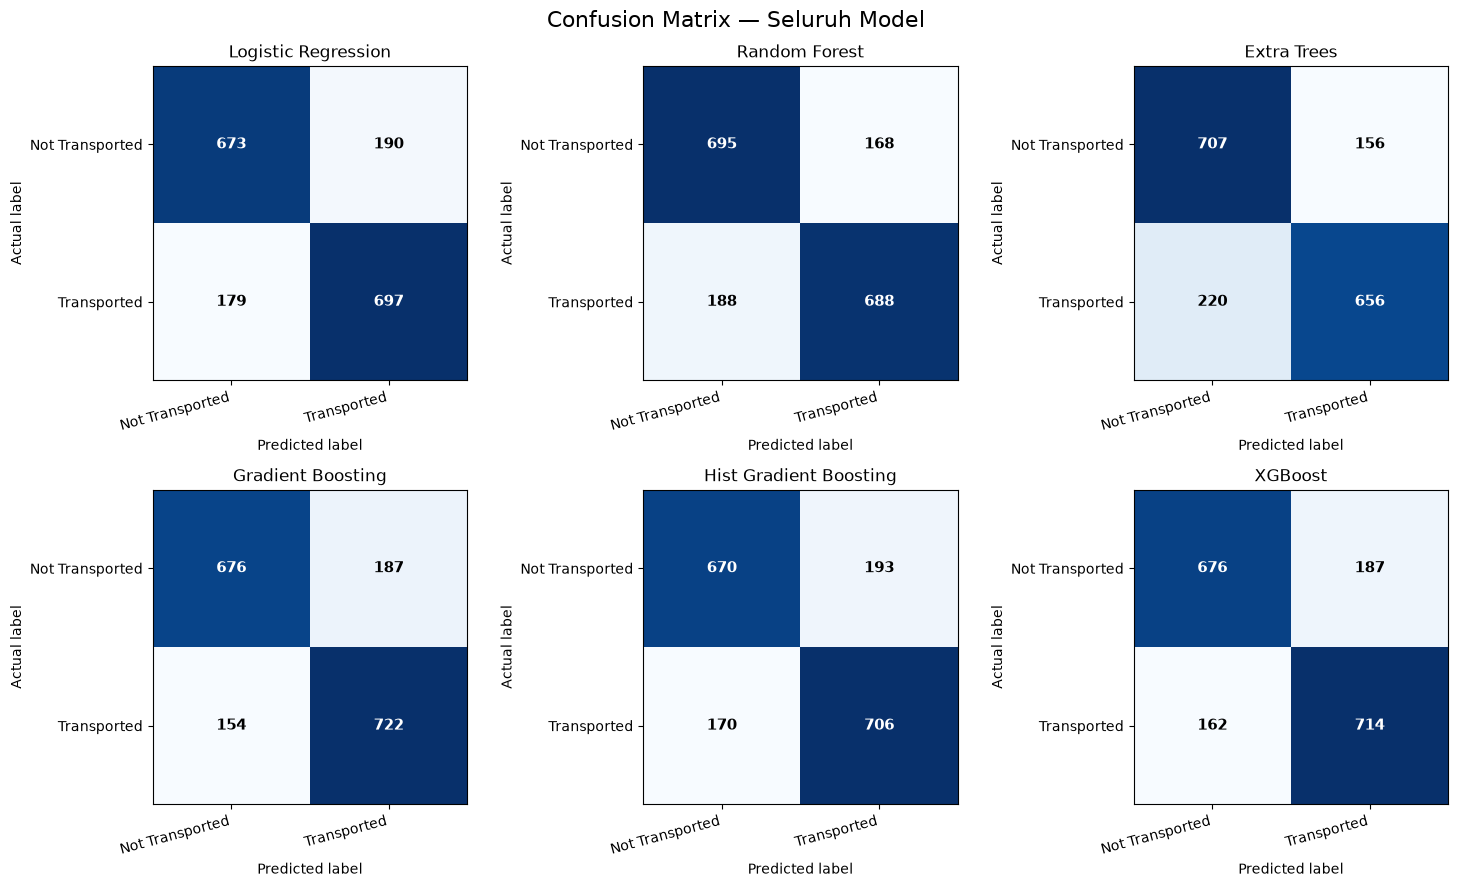

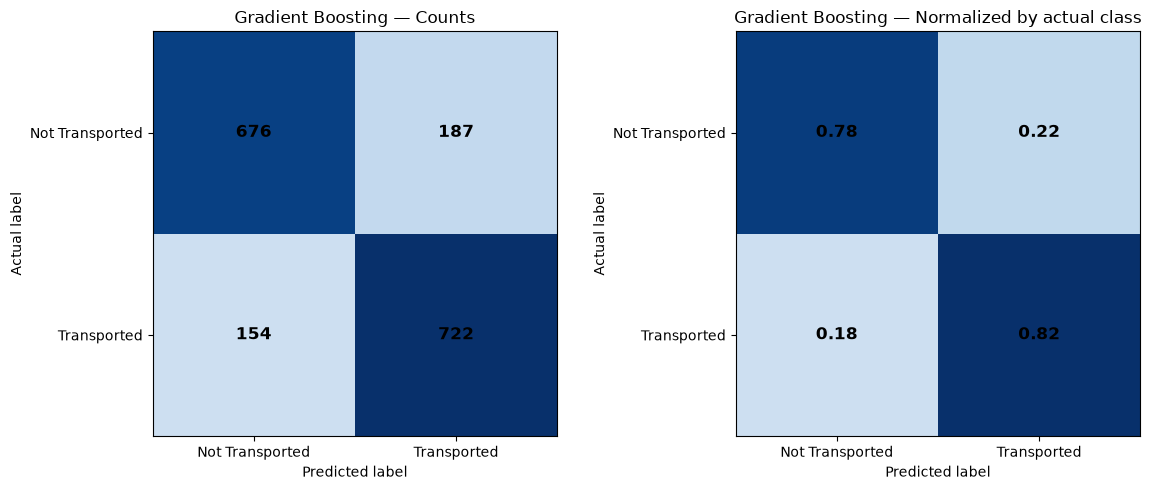

Classification Report — Gradient Boosting
                         precision    recall  f1-score   support

Not Transported (False)     0.8145    0.7833    0.7986       863
     Transported (True)     0.7943    0.8242    0.8090       876

               accuracy                         0.8039      1739
              macro avg     0.8044    0.8038    0.8038      1739
           weighted avg     0.8043    0.8039    0.8038      1739

Metrik model terbaik:


,Value
Model,Gradient Boosting
Accuracy,0.80391
Balanced Accuracy,0.803757
Precision,0.794279
Recall / Sensitivity,0.824201
Specificity,0.783314
F1-Score,0.808964
ROC-AUC,0.892471
PR-AUC (Average Precision),0.902311
Log Loss,0.412692


In [9]:
# A. Perbandingan metrik seluruh model
metric_cols = [
    'Accuracy', 'Balanced Accuracy', 'Precision',
    'Recall / Sensitivity', 'Specificity', 'F1-Score', 'ROC-AUC'
]
fig, ax = plt.subplots(figsize=(16, 7))
results_df.set_index('Model')[metric_cols].plot(kind='bar', ax=ax, width=0.82)
ax.set_title('Perbandingan Metrik Validasi Seluruh Model', fontsize=15)
ax.set_ylabel('Score')
ax.set_xlabel('Model')
ax.set_ylim(0, 1.05)
ax.grid(axis='y', alpha=0.25)
ax.legend(loc='lower right', ncol=2)
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
fig.savefig(PLOT_DIR / '01_model_metric_comparison.png', dpi=160, bbox_inches='tight')
plt.show()

# B. ROC curve semua model
fig, ax = plt.subplots(figsize=(8, 7))
for name in models:
    fpr, tpr, _ = roc_curve(y_valid, valid_probabilities[name])
    auc_value = results_df.loc[results_df['Model'] == name, 'ROC-AUC'].iloc[0]
    ax.plot(fpr, tpr, linewidth=2, label=f'{name} (AUC={auc_value:.4f})')
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random classifier')
ax.set_title('ROC Curve — Validation Set')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.grid(alpha=0.25)
ax.legend(loc='lower right')
plt.tight_layout()
fig.savefig(PLOT_DIR / '02_roc_curves.png', dpi=160, bbox_inches='tight')
plt.show()

# C. Precision-Recall curve semua model
fig, ax = plt.subplots(figsize=(8, 7))
for name in models:
    precision_values, recall_values, _ = precision_recall_curve(
        y_valid, valid_probabilities[name]
    )
    ap_value = results_df.loc[
        results_df['Model'] == name, 'PR-AUC (Average Precision)'
    ].iloc[0]
    ax.plot(recall_values, precision_values, linewidth=2, label=f'{name} (AP={ap_value:.4f})')
baseline_rate = y_valid.mean()
ax.axhline(baseline_rate, linestyle='--', color='gray',
           label=f'Baseline positive rate ({baseline_rate:.3f})')
ax.set_title('Precision–Recall Curve — Validation Set')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.grid(alpha=0.25)
ax.legend(loc='lower left')
plt.tight_layout()
fig.savefig(PLOT_DIR / '03_precision_recall_curves.png', dpi=160, bbox_inches='tight')
plt.show()

# D. Confusion matrix untuk setiap model (angka absolut)
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, name in zip(axes.ravel(), models):
    cm = confusion_matrix(y_valid, valid_predictions[name], labels=[0, 1])
    im = ax.imshow(cm, cmap='Blues')
    ax.set_title(name)
    ax.set_xlabel('Predicted label')
    ax.set_ylabel('Actual label')
    ax.set_xticks([0, 1], ['Not Transported', 'Transported'], rotation=15, ha='right')
    ax.set_yticks([0, 1], ['Not Transported', 'Transported'])
    threshold = cm.max() / 2 if cm.max() else 0
    for row in range(2):
        for col in range(2):
            ax.text(col, row, f'{cm[row, col]:,}', ha='center', va='center',
                    color='white' if cm[row, col] > threshold else 'black',
                    fontsize=11, fontweight='bold')
fig.suptitle('Confusion Matrix — Seluruh Model', fontsize=16)
fig.tight_layout()
fig.savefig(PLOT_DIR / '04_confusion_matrices_all_models.png', dpi=160, bbox_inches='tight')
plt.show()

# E. Confusion matrix model terbaik: absolut dan normalisasi per kelas aktual.
best_cm = confusion_matrix(y_valid, best_valid_pred, labels=[0, 1])
best_cm_norm = confusion_matrix(y_valid, best_valid_pred, labels=[0, 1], normalize='true')

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, matrix, title, fmt in [
    (axes[0], best_cm, 'Counts', 'd'),
    (axes[1], best_cm_norm, 'Normalized by actual class', '.2f')
]:
    ax.imshow(matrix, cmap='Blues', vmin=0)
    ax.set_title(f'{best_model_name} — {title}')
    ax.set_xlabel('Predicted label')
    ax.set_ylabel('Actual label')
    ax.set_xticks([0, 1], ['Not Transported', 'Transported'])
    ax.set_yticks([0, 1], ['Not Transported', 'Transported'])
    for row in range(2):
        for col in range(2):
            value = format(matrix[row, col], fmt) if fmt == 'd' else format(matrix[row, col], fmt)
            ax.text(col, row, value, ha='center', va='center', fontsize=12, fontweight='bold')
fig.tight_layout()
fig.savefig(PLOT_DIR / '05_best_model_confusion_matrix.png', dpi=160, bbox_inches='tight')
plt.show()

# F. Classification report model terbaik
print(f'Classification Report — {best_model_name}')
print(classification_report(
    y_valid, best_valid_pred,
    labels=[0, 1],
    target_names=['Not Transported (False)', 'Transported (True)'],
    digits=4, zero_division=0
))

print('Metrik model terbaik:')
display(results_df.loc[results_df['Model'] == best_model_name].T.rename(columns={0: 'Value'}))

## 10. 5-Fold Stratified Cross-Validation

Cross-validation dijalankan untuk **semua model**, bukan hanya model yang menang pada satu validation split. Metrik mean dan standard deviation digunakan untuk melihat performa sekaligus kestabilan model antar-fold.

5-fold CV: Logistic Regression ...
5-fold CV: Random Forest ...
5-fold CV: Extra Trees ...
5-fold CV: Gradient Boosting ...
5-fold CV: Hist Gradient Boosting ...
5-fold CV: XGBoost ...


,Model,ACCURACY Mean,ACCURACY Std,PRECISION Mean,PRECISION Std,RECALL Mean,RECALL Std,F1 Mean,F1 Std,ROC_AUC Mean,ROC_AUC Std
0,XGBoost,0.7993,0.0041,0.7898,0.0069,0.8198,0.0122,0.8044,0.0048,0.8874,0.0044
1,Hist Gradient Boosting,0.7991,0.0072,0.7873,0.0081,0.8239,0.0114,0.8051,0.0073,0.8861,0.0049
2,Gradient Boosting,0.7967,0.0072,0.7815,0.0049,0.8278,0.0157,0.8039,0.0084,0.8851,0.0046
3,Random Forest,0.7922,0.0065,0.7985,0.0060,0.7857,0.0127,0.7920,0.0075,0.8775,0.0051
4,Extra Trees,0.7896,0.0044,0.8057,0.0027,0.7672,0.0116,0.7860,0.0059,0.8735,0.0045
5,Logistic Regression,0.7871,0.0102,0.7744,0.0095,0.8145,0.0162,0.7939,0.0107,0.8713,0.0040


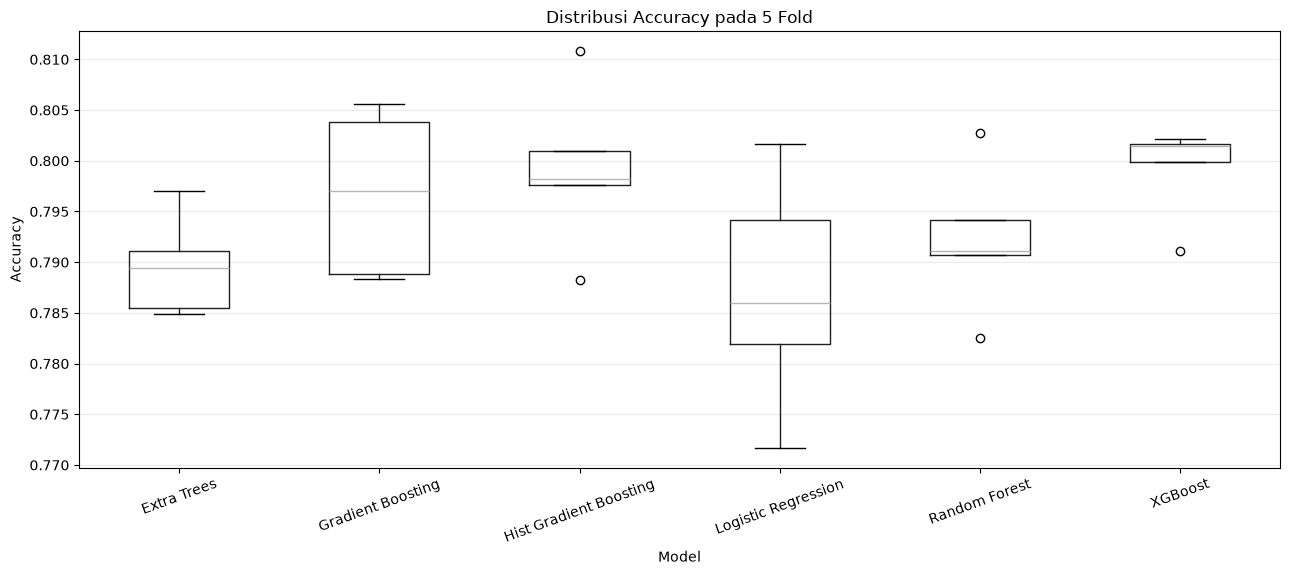

In [10]:
RUN_CV = True

if RUN_CV:
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    scoring = {
        'accuracy': 'accuracy',
        'precision': 'precision',
        'recall': 'recall',
        'f1': 'f1',
        'roc_auc': 'roc_auc'
    }

    cv_rows = []
    cv_fold_results = {}

    for name, pipeline in models.items():
        print(f'5-fold CV: {name} ...')
        cv_result = cross_validate(
            clone(pipeline), X, y, cv=cv,
            scoring=scoring, n_jobs=1,
            return_train_score=False, error_score='raise'
        )
        cv_fold_results[name] = cv_result
        row = {'Model': name}
        for metric in scoring:
            row[f'{metric.upper()} Mean'] = cv_result[f'test_{metric}'].mean()
            row[f'{metric.upper()} Std'] = cv_result[f'test_{metric}'].std()
        cv_rows.append(row)

    cv_results = (
        pd.DataFrame(cv_rows)
        .sort_values('ACCURACY Mean', ascending=False)
        .reset_index(drop=True)
    )
    display(cv_results.style.format({
        col: '{:.4f}' for col in cv_results.select_dtypes(include='number').columns
    }))

    # Visualisasi accuracy dan F1 per fold agar kestabilan terlihat.
    fold_plot_data = []
    for name, cv_result in cv_fold_results.items():
        for fold_idx, score in enumerate(cv_result['test_accuracy'], start=1):
            fold_plot_data.append({'Model': name, 'Fold': fold_idx, 'Accuracy': score})
    fold_plot_df = pd.DataFrame(fold_plot_data)

    fig, ax = plt.subplots(figsize=(13, 6))
    fold_plot_df.boxplot(column='Accuracy', by='Model', ax=ax, grid=False, rot=20)
    ax.set_title('Distribusi Accuracy pada 5 Fold')
    fig.suptitle('')
    ax.set_xlabel('Model')
    ax.set_ylabel('Accuracy')
    ax.grid(axis='y', alpha=0.25)
    plt.tight_layout()
    fig.savefig(PLOT_DIR / '06_cv_accuracy_boxplot.png', dpi=160, bbox_inches='tight')
    plt.show()
else:
    cv_results = pd.DataFrame()
    print('Cross-validation dilewati (RUN_CV=False).')

## 11. Fit ulang model terbaik dan buat submission

In [11]:
final_model = clone(best_model)
final_model.fit(X, y)

test_predictions = final_model.predict(X_test).astype(bool)
submission = sample_submission[['PassengerId']].copy()
submission['Transported'] = test_predictions

# Pemeriksaan format sebelum file disimpan.
assert len(submission) == len(test), 'Jumlah baris submission tidak sama dengan test.csv.'
assert submission['PassengerId'].equals(test['PassengerId']), 'Urutan PassengerId tidak cocok dengan test.csv.'
assert submission['Transported'].notna().all(), 'Prediksi mengandung nilai kosong.'
assert submission['Transported'].isin([True, False]).all(), 'Target harus berupa Boolean.'

submission_path = OUTPUT_DIR / 'submission.csv'
submission.to_csv(submission_path, index=False)
print('Submission saved:', submission_path)
print('Rows:', len(submission))
print(submission['Transported'].value_counts())
display(submission.head(10))


Submission saved: d:\MKA\PMA\Spaceship_Titanic_VSCode\outputs\submission.csv
Rows: 4277
Transported
True     2308
False    1969
Name: count, dtype: int64


,PassengerId,Transported
0,0013_01,True
1,0018_01,False
2,0019_01,True
3,0021_01,True
4,0023_01,True
5,0027_01,True
6,0029_01,True
7,0032_01,True
8,0032_02,True
9,0033_01,True


## 12. Simpan model, metrik, dan grafik evaluasi

Model terbaik, tabel metrik validation, hasil cross-validation, ringkasan eksperimen, serta seluruh grafik evaluasi disimpan di folder output.

In [12]:
model_filename = best_model_name.lower().replace(' ', '_').replace('-', '_') + '_model.joblib'
model_path = MODEL_DIR / model_filename
results_path = OUTPUT_DIR / 'validation_results.csv'
cv_results_path = OUTPUT_DIR / 'cross_validation_results.csv'

joblib.dump(final_model, model_path)
results_df.to_csv(results_path, index=False)
if RUN_CV and not cv_results.empty:
    cv_results.to_csv(cv_results_path, index=False)

# Simpan ringkasan konfigurasi dan metrik model terpilih.
best_row = results_df.iloc[0].to_dict()
run_info = {
    'competition': 'spaceship-titanic',
    'random_state': RANDOM_STATE,
    'selected_model': best_model_name,
    'selection_metric': 'Validation Accuracy',
    'validation_metrics': {
        key: (float(value) if isinstance(value, (np.floating, float, np.integer, int)) else value)
        for key, value in best_row.items()
    },
    'train_rows': int(len(train)),
    'test_rows': int(len(test)),
    'features': X.columns.tolist(),
}
with open(OUTPUT_DIR / 'run_info.json', 'w') as f:
    json.dump(run_info, f, indent=2)

print('Files ready for download:')
for path in sorted(OUTPUT_DIR.rglob('*')):
    if path.is_file():
        print(path, f'({path.stat().st_size / 1024:.1f} KB)')

Files ready for download:
d:\MKA\PMA\Spaceship_Titanic_VSCode\outputs\cross_validation_results.csv (1.4 KB)
d:\MKA\PMA\Spaceship_Titanic_VSCode\outputs\models\gradient_boosting_model.joblib (336.0 KB)
d:\MKA\PMA\Spaceship_Titanic_VSCode\outputs\plots\01_model_metric_comparison.png (84.4 KB)
d:\MKA\PMA\Spaceship_Titanic_VSCode\outputs\plots\02_roc_curves.png (123.0 KB)
d:\MKA\PMA\Spaceship_Titanic_VSCode\outputs\plots\03_precision_recall_curves.png (135.8 KB)
d:\MKA\PMA\Spaceship_Titanic_VSCode\outputs\plots\04_confusion_matrices_all_models.png (172.2 KB)
d:\MKA\PMA\Spaceship_Titanic_VSCode\outputs\plots\05_best_model_confusion_matrix.png (59.6 KB)
d:\MKA\PMA\Spaceship_Titanic_VSCode\outputs\plots\06_cv_accuracy_boxplot.png (65.3 KB)
d:\MKA\PMA\Spaceship_Titanic_VSCode\outputs\run_info.json (1.1 KB)
d:\MKA\PMA\Spaceship_Titanic_VSCode\outputs\submission.csv (60.4 KB)
d:\MKA\PMA\Spaceship_Titanic_VSCode\outputs\submission_baseline.csv (60.5 KB)
d:\MKA\PMA\Spaceship_Titanic_VSCode\outputs

## 13. Arsipkan seluruh hasil

Cell ini membuat file `spaceship_titanic_outputs.zip` di folder project. Arsip berisi `submission.csv`, model terpilih, tabel evaluasi, hasil cross-validation, ringkasan eksperimen, dan grafik evaluasi.

In [13]:
# Buat arsip ZIP lokal agar semua hasil mudah dibagikan.
archive_base = PROJECT_DIR / "spaceship_titanic_outputs"
output_zip = shutil.make_archive(
    str(archive_base),
    "zip",
    root_dir=OUTPUT_DIR
)

print("Arsip hasil berhasil dibuat:")
print(output_zip)
print("Kamu dapat membukanya melalui File Explorer pada folder project.")

Arsip hasil berhasil dibuat:
d:\MKA\PMA\Spaceship_Titanic_VSCode\spaceship_titanic_outputs.zip
Kamu dapat membukanya melalui File Explorer pada folder project.
